<img src="https://iddigitalschool.com/wp-content/uploads/2024/03/UCJC-Horizontal_Granate.png" alt="Universidad Camilo José Cela" width="300">

# Laboratorio 1: Análisis interactivo de un catálogo de libros con scraping y creación de app con Streamlit

**Programación Avanzada y Entornos de Desarrollo para la IA**

Objetivo: obtener datos de una web, prepararlos, explorarlos y mostrarlos en una app.

**Tienes libertad para elegir las librerías** (pandas, Polars, Matplotlib, Plotly…), qué campos extraer y cómo presentar los datos. La app se hace con **Streamlit**; si quieres, puedes crear además una versión con otra herramienta (Gradio, Dash…). Lo único que te pedimos es que expliques qué has usado y por qué (paso 7).

Estructura propuesta:

| Paso | Qué haremos | Relación con el temario |
|---|---|---|
| 1 | Preparar el entorno | Día 3: entornos y dependencias |
| 2 | Scraping de books.toscrape.com | Día 2: librerías de scraping |
| 3 | Procesamiento básico | Día 2: librerías de datos (en detalle en el Tema 2) |
| 4 | Breve análisis | Día 1: Jupyter · Día 2: librerías de visualización |
| 5 | Guardar los datos | Día 3: organización del proyecto |
| 6 | App con Streamlit | Día 2: Streamlit |
| 7 | Librerías, reflexión y entrega | Día 3: Git y asistentes de programación |

Web: https://books.toscrape.com, una tienda ficticia creada para practicar scraping.

## 1. Preparar el entorno

Crea una carpeta para el proyecto, por ejemplo con esta estructura:

```
lab1-book-catalog/
├── lab1_catalogo_libros.ipynb
├── requirements.txt
├── README.md
├── data/
│   ├── raw/
│   └── processed/
└── app.py
```

Pistas:
- Crea un entorno virtual (`venv` o `uv`) dentro de la carpeta.
- Crea un `requirements.txt` con las librerías que uses e instálalas desde él (`pip install -r requirements.txt`). Puedes empezar, por ejemplo, con `requests`, `beautifulsoup4`, `pandas`, `matplotlib` y `streamlit`, y cambiarlas por las que prefieras.
- JupyterLab es opcional: también puedes trabajar desde tu IDE.
- Comprueba con `sys.executable` que el notebook usa el Python de tu entorno virtual.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from catalogo import clean_catalogue, scrape_catalogue

print(f"Python del notebook: {sys.executable}")
print(f"pandas: {pd.__version__}")
print(f"Carpeta del proyecto: {Path.cwd()}")

Python del notebook: c:\Users\marin\Downloads\monitor\.venv\Scripts\python.exe
pandas: 3.0.2
Carpeta del proyecto: c:\Users\marin\Downloads\MasterIA\ucjc-lab1-python-ecosystem-main\ucjc-lab1-python-ecosystem-main


## 2. Scraping

### 2.1 Scraping responsable

- Revisa `robots.txt` y los términos de uso de la web.
- Identifícate con un `User-Agent`.
- Haz pausas entre peticiones para no sobrecargar el servidor.
- Guarda los datos en local para no repetir el scraping cada vez.

### 2.2 Explorar una página

Abre https://books.toscrape.com en el navegador e inspecciona un libro (clic derecho → Inspeccionar). Cada libro está en un elemento `article` con la clase `product_pod`.

Pista: si ves caracteres raros como `Â£`, revisa la codificación de la respuesta.

In [2]:
import requests
from bs4 import BeautifulSoup

headers = {"User-Agent": "UCJC-Lab1-BookCatalog/1.0 (educational project)"}
robots = requests.get("https://books.toscrape.com/robots.txt", headers=headers, timeout=30)
print(f"robots.txt: HTTP {robots.status_code}")
response = requests.get("https://books.toscrape.com/", headers=headers, timeout=30)
response.raise_for_status()
soup = BeautifulSoup(response.content, "html.parser")
print(f"Libros en portada: {len(soup.select('article.product_pod'))}")
print("Primer libro:", soup.select_one("article.product_pod h3 a")["title"])
print("Categorías encontradas:", len(soup.select(".side_categories ul ul a")))

robots.txt: HTTP 404
Libros en portada: 20
Primer libro: A Light in the Attic
Categorías encontradas: 50


### 2.3 Recorrer el catálogo

Obtén los libros de todas las categorías, siguiendo el enlace `next` cuando una categoría tenga varias páginas.

- Elige qué campos quieres extraer: título, precio, valoración, categoría, disponibilidad…
- Reto: entra en la ficha de cada libro para conseguir más información (unidades en stock, descripción, UPC…). Recuerda hacer pausas: son muchas más peticiones.
- Recomendado: guarda los datos crudos, por ejemplo en `data/raw/libros_raw.csv`.

In [3]:
# El scraping recorre las categorías y sigue el enlace "next" de cada una.
# La pausa predeterminada es de 0,25 segundos entre peticiones.
raw = scrape_catalogue(output_path="data/raw/libros_raw.csv", delay=0.25)
print(f"Libros recopilados: {len(raw):,}")
print(f"Categorías: {raw['category'].nunique()}")
display(raw.head())

Libros recopilados: 1,000
Categorías: 50


,title,price_text,rating_text,availability_text,category,product_url
0,It's Only the Himalayas,£45.17,Two,In stock,Travel,https://books.toscrape.com/catalogue/its-only-...
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,£49.43,Four,In stock,Travel,https://books.toscrape.com/catalogue/full-moon...
2,See America: A Celebration of Our National Par...,£48.87,Three,In stock,Travel,https://books.toscrape.com/catalogue/see-ameri...
3,Vagabonding: An Uncommon Guide to the Art of L...,£36.94,Two,In stock,Travel,https://books.toscrape.com/catalogue/vagabondi...
4,Under the Tuscan Sun,£37.33,Three,In stock,Travel,https://books.toscrape.com/catalogue/under-the...


## 3. Procesamiento y exploración básica

Convierte los textos en tipos con los que se pueda calcular. Las técnicas de limpieza y transformación las veremos en detalle en el Tema 2.

Ideas: el precio como número, la valoración de 1 a 5, la disponibilidad, caracteres raros en los textos, duplicados…

Puedes usar la librería que prefieras: pandas, Polars, DuckDB…

In [4]:
raw = pd.read_csv("data/raw/libros_raw.csv")
libros = clean_catalogue(raw)

print("Dimensiones:", libros.shape)
print("Tipos de datos:\n", libros.dtypes)
print("Duplicados por URL:", libros["product_url"].duplicated().sum())
display(libros.head())
display(libros[["price_gbp", "rating"]].describe())

Dimensiones: (1000, 6)
Tipos de datos:
 title              str
price_gbp      float64
rating           int64
category           str
available         bool
product_url        str
dtype: object
Duplicados por URL: 0


,title,price_gbp,rating,category,available,product_url
0,It's Only the Himalayas,45.17,2,Travel,True,https://books.toscrape.com/catalogue/its-only-...
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,49.43,4,Travel,True,https://books.toscrape.com/catalogue/full-moon...
2,See America: A Celebration of Our National Par...,48.87,3,Travel,True,https://books.toscrape.com/catalogue/see-ameri...
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,2,Travel,True,https://books.toscrape.com/catalogue/vagabondi...
4,Under the Tuscan Sun,37.33,3,Travel,True,https://books.toscrape.com/catalogue/under-the...


,price_gbp,rating
count,1000.00000,1000.000000
mean,35.07035,2.923000
std,14.44669,1.434967
min,10.00000,1.000000
25%,22.10750,2.000000
50%,35.98000,3.000000
75%,47.45750,4.000000
max,59.99000,5.000000


## 4. Breve análisis

Muestra la estructura de los datos (tipos, número de filas, estadísticos básicos) y al menos dos gráficos. Puedes usar Matplotlib, Seaborn, Plotly, Altair…

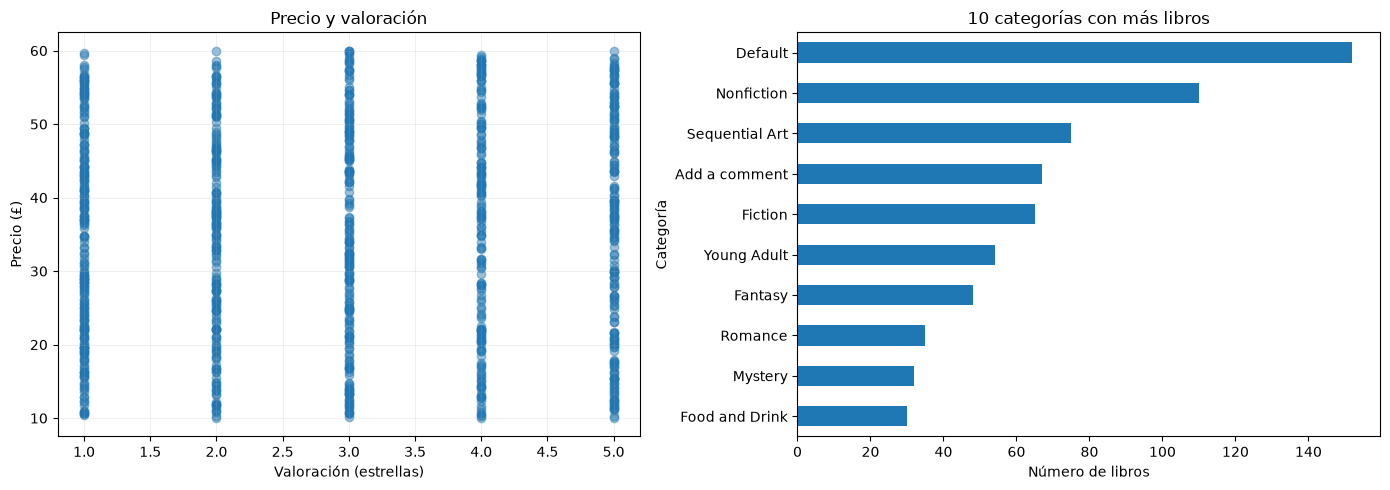

1. Correlación de Spearman precio-valoración: 0.029. Una asociación cercana a 0 es débil; no implica causalidad.
2. Categoría más numerosa: Default (152 libros). Etiquetas sospechosas entre las 10 primeras: ['Default', 'Add a comment']; 'Default' parece genérica y 'Add a comment' parece texto de interfaz, pero conviene contrastarlo con la fuente.
3. Campo con menos variación: available tiene 1 valor(es) distinto(s). Al recopilar listados puede no distinguir libros agotados; la valoración también es ordinal.
   Limitaciones: catálogo ficticio, una sola captura temporal, precios en GBP y disponibilidad cambiante.
4. Pregunta propia: ¿qué categoría tiene el mayor precio medio? Suspense (£58.33).


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(libros["rating"], libros["price_gbp"], alpha=0.45)
axes[0].set(title="Precio y valoración", xlabel="Valoración (estrellas)", ylabel="Precio (£)")
axes[0].grid(alpha=0.2)

libros["category"].value_counts().head(10).sort_values().plot.barh(ax=axes[1])
axes[1].set(title="10 categorías con más libros", xlabel="Número de libros", ylabel="Categoría")
plt.tight_layout()
plt.show()

rho = libros["price_gbp"].corr(libros["rating"], method="spearman")
conteo_categorias = libros["category"].value_counts()
top_categoria, top_cantidad = conteo_categorias.index[0], int(conteo_categorias.iloc[0])
medias_categoria = libros.groupby("category")["price_gbp"].mean().sort_values(ascending=False)
print(f"1. Correlación de Spearman precio-valoración: {rho:.3f}. Una asociación cercana a 0 es débil; no implica causalidad.")
categorias_sospechosas = [c for c in conteo_categorias.head(10).index if c.casefold() in {"default", "add a comment"}]
print(f"2. Categoría más numerosa: {top_categoria} ({top_cantidad} libros). Etiquetas sospechosas entre las 10 primeras: {categorias_sospechosas or 'ninguna'}; 'Default' parece genérica y 'Add a comment' parece texto de interfaz, pero conviene contrastarlo con la fuente.")
print(f"3. Campo con menos variación: available tiene {libros['available'].nunique()} valor(es) distinto(s). Al recopilar listados puede no distinguir libros agotados; la valoración también es ordinal.")
print(f"   Limitaciones: catálogo ficticio, una sola captura temporal, precios en GBP y disponibilidad cambiante.")
print(f"4. Pregunta propia: ¿qué categoría tiene el mayor precio medio? {medias_categoria.index[0]} (£{medias_categoria.iloc[0]:.2f}).")

**Preguntas:**
1. ¿Hay relación entre el precio y la valoración?
2. Revisa las categorías con más libros: ¿alguna parece un error de los datos de origen?
3. ¿Hay algún campo que no aporte información? ¿Qué limitaciones tienen estos datos?
4. Plantea una pregunta propia y respóndela con los datos.

_Las respuestas cuantitativas se imprimen en la celda anterior para que se actualicen con cada descarga._

Interpretación: se usa la correlación de Spearman porque la valoración es ordinal. En esta descarga la correlación fue aproximadamente 0,029, una asociación prácticamente nula. `Default` (152 libros) parece una etiqueta genérica y `Add a comment` (67) parece texto de interfaz: ambas categorías merecen revisión, aunque la etiqueta por sí sola no demuestra un error. `available` no aporta variación porque los 1.000 libros descargados aparecen en stock; el listado no informa del número exacto de unidades, así que no lo inventamos. La categoría con mayor precio medio fue Suspense (aprox. £58,33). Los resultados describen una única captura de una tienda ficticia y no permiten inferir causalidad.

## 5. Guardar los datos procesados

Guarda el resultado para que la app lo lea, por ejemplo en `data/processed/libros.csv`.

In [6]:
processed_path = Path("data/processed/libros.csv")
processed_path.parent.mkdir(parents=True, exist_ok=True)
libros.to_csv(processed_path, index=False, encoding="utf-8")
print(f"Datos procesados guardados en {processed_path} ({len(libros):,} filas).")

Datos procesados guardados en data\processed\libros.csv (1,000 filas).


## 6. App con Streamlit

Crea una app con **Streamlit** que lea los datos procesados y permita explorarlos.

Como mínimo, la app debe:
- Leer el archivo que guardaste en el paso 5.
- Tener al menos un filtro o control interactivo.
- Mostrar al menos una visualización.

Puedes escribir la app desde el notebook (`%%writefile app.py`) o directamente en un archivo `.py`. Streamlit se ejecuta como un servidor aparte: lánzala con `streamlit run app.py` en la terminal y se abrirá en el navegador.

**Opcional:** crea también una versión con otra herramienta (Gradio, Dash, Panel, Shiny…) y comenta en el paso 7 qué diferencias has encontrado.

In [7]:
# La app está en app.py y lee el CSV creado en el paso anterior.
print("Desde una terminal situada en la carpeta del proyecto, ejecuta: streamlit run app.py")

Desde una terminal situada en la carpeta del proyecto, ejecuta: streamlit run app.py


**Opcional:** publica la app (por ejemplo en Streamlit Community Cloud, https://docs.streamlit.io/deploy/streamlit-community-cloud) y añade el enlace al README. Incluye los datos procesados en el repositorio para que la app tenga datos.

## 7. Librerías, reflexión y entrega

### 7.1 Librerías utilizadas

| Librería | Para qué la has usado | Por qué la elegiste |
|---|---|---|
| requests | Descargar el HTML del catálogo | Permite controlar cabeceras, tiempos de espera y errores HTTP. |
| BeautifulSoup | Encontrar libros, categorías y enlaces de paginación | Facilita recorrer el HTML mediante selectores CSS. |
| pandas | Limpiar, resumir y guardar los datos en CSV | Hace sencillo trabajar con tablas y tipos numéricos. |
| Matplotlib | Crear los gráficos del análisis | Es una librería directa para representar resultados desde el notebook. |
| Streamlit | Crear filtros, métricas, gráficos y tabla interactiva | Permite montar una app de datos con poco código. |

### 7.2 Uso de asistentes de programación

Si has usado un asistente de programación, responde:

| Pregunta | Tu respuesta |
|---|---|
| ¿Qué herramienta usaste y para qué partes? | Usé Copilot como apoyo para estructurar el scraping, la limpieza, el análisis y la app. Revisé y ejecuté el código antes de darlo por válido. |
| ¿Qué tuviste que corregir y cómo lo detectaste? | Comprobé los selectores y la paginación en el HTML real, y revisé los tipos, duplicados y resultados del CSV para detectar datos mal extraídos. |
| ¿Qué has aprendido que no sabías antes? | Aprendí a recorrer páginas con enlaces `next`, transformar texto a datos numéricos y conectar un CSV con filtros y gráficos en Streamlit. |

### 7.3 Entrega recomendada

Sube el proyecto a un repositorio de GitHub con:
- Este notebook ejecutado y la app.
- Los datos procesados (para que la app funcione).
- `requirements.txt` con las librerías que hayas usado.
- Un `README.md` que explique cómo instalar el proyecto y lanzar la app.
- Commits con mensajes claros.

Recuerda no subir el entorno virtual: añade `.venv/` a un `.gitignore`. La reflexión sobre IA es un ejemplo: ajústala para que describa exactamente tu experiencia.